# Lecture 9 notebook: Sizing trend systems

Companion to Lecture 9 of *Systematic Trading Notes*; sections are numbered as in the lecture. The same signals are
sized in different ways, so that every difference in the results comes from sizing alone.

Data: the 16 ETFs of Lectures 5 and 6, daily, 2000–2026. Positions are decided at the close of day $t$ and earn the
return of day $t+1$. Results on one history are preliminary.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from plotly.subplots import make_subplots

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "09-sizing-trend-systems" / "figures"
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]
D = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb05_ohlc.csv")
C, H, L = (D[f][TICKERS] for f in ("close", "high", "low"))
r = np.log(C).diff()
vol = r.ewm(span=60, min_periods=60).std()
TARGET = 0.10 / np.sqrt(252)
START = "2000-01-01"


def stats(x):
    x = x.loc[START:].dropna()
    cum = x.cumsum()
    m = x.resample("ME").sum()
    return {"return % a year": 100 * 252 * x.mean(), "volatility %": 100 * np.sqrt(252) * x.std(),
            "Sharpe ratio": np.sqrt(252) * x.mean() / x.std(), "monthly skewness": m.skew(),
            "worst month %": 100 * m.min(), "max drawdown %": 100 * (cum - cum.cummax()).min()}


def portfolio(pos):
    return (pos.shift(1) * r).mean(axis=1)


def same_vol(x, ref):
    # rescale x to the full-sample volatility of ref (a constant, for comparison only)
    return x * ref.loc[START:].std() / x.loc[START:].std()

## 2. Five sizing formulas, by hand (Table 2.1)

One asset at a price of 100, capital of USD 1 million.

In [2]:
capital, price = 1_000_000, 100.0
atr, k, risk_per_trade = 2.0, 3.0, 0.01
units_stop = risk_per_trade * capital / (k * atr)
asset_vol, target_vol = 0.20, 0.10
w_invvol = target_vol / asset_vol
port_vol_now = 0.15
mult_port = 0.10 / port_vol_now
dd, dd_max = 0.10, 0.20
mult_dd = max(0.0, 1 - dd / dd_max)
mu, sigma = 0.05, 0.20
kelly = mu / sigma ** 2
print(f"stop distance: risk {risk_per_trade:.0%} of capital, stop {k} ATR = {k * atr:.1f} below entry -> {units_stop:,.0f} shares = {units_stop * price / capital:.0%} of capital")
print(f"inverse volatility: asset volatility {asset_vol:.0%}, target {target_vol:.0%} -> exposure {w_invvol:.2f} x capital")
print(f"portfolio target: book running at {port_vol_now:.0%}, target 10% -> scale every position by {mult_port:.2f}")
print(f"drawdown control: drawdown {dd:.0%} with a limit of {dd_max:.0%} -> exposure multiplier {mult_dd:.2f}")
print(f"Kelly: expected excess return {mu:.0%}, volatility {sigma:.0%} -> full Kelly leverage {kelly:.2f}, half Kelly {kelly / 2:.2f}")

stop distance: risk 1% of capital, stop 3.0 ATR = 6.0 below entry -> 1,667 shares = 17% of capital
inverse volatility: asset volatility 20%, target 10% -> exposure 0.50 x capital
portfolio target: book running at 15%, target 10% -> scale every position by 0.67
drawdown control: drawdown 10% with a limit of 20% -> exposure multiplier 0.50
Kelly: expected excess return 5%, volatility 20% -> full Kelly leverage 1.25, half Kelly 0.62


## 3. Per trade and per asset (Table 3.1)

Two signals: the 12-month return sign (TSMOM-12) and a 55-day breakout with a chandelier stop (3 ATR). Sizing by
equal notional, by inverse volatility, and, for the breakout, by stop distance (1% of capital at risk per trade).
All versions rescaled to the volatility of the inverse-volatility version for comparison.

In [3]:
def chandelier(entry=55, k=3.0, n_atr=20):
    tr = pd.concat({t: pd.concat([H[t] - L[t], (H[t] - C[t].shift()).abs(), (L[t] - C[t].shift()).abs()], axis=1).max(axis=1) for t in TICKERS}, axis=1)
    atr_ = tr.rolling(n_atr).mean()
    he, le = C.rolling(entry).max().shift(1), C.rolling(entry).min().shift(1)
    out = pd.DataFrame(0.0, index=C.index, columns=TICKERS)
    for t in TICKERS:
        pos, ext, ps = 0.0, np.nan, []
        for px, a, b, at in zip(C[t].to_numpy(), he[t].to_numpy(), le[t].to_numpy(), atr_[t].to_numpy()):
            if np.isnan(px) or np.isnan(a) or np.isnan(at):
                pos = 0.0
            elif pos == 0:
                if px > a:
                    pos, ext = 1.0, px
                elif px < b:
                    pos, ext = -1.0, px
            elif pos == 1:
                ext = max(ext, px)
                if px < ext - k * at:
                    pos = 0.0
            else:
                ext = min(ext, px)
                if px > ext + k * at:
                    pos = 0.0
            ps.append(pos)
        out[t] = ps
    return out, atr_


tsm = np.sign(np.log(C).diff(252))
brk, atr20 = chandelier()
rows = {}
ts_iv = portfolio(tsm * TARGET / vol)
rows["TSMOM-12, equal notional"] = stats(same_vol(portfolio(tsm), ts_iv))
rows["TSMOM-12, inverse volatility"] = stats(ts_iv)
br_iv = portfolio(brk * TARGET / vol)
rows["Breakout, equal notional"] = stats(same_vol(portfolio(brk), br_iv))
rows["Breakout, inverse volatility"] = stats(br_iv)
stop_units = brk * 0.01 / (3 * atr20 / C)               # exposure as a share of capital: 1% risk over a 3-ATR stop
rows["Breakout, stop distance (1% per trade)"] = stats(same_vol(portfolio(stop_units), br_iv))
display(pd.DataFrame(rows).T.round(2))
sz = pd.concat([(TARGET / vol).loc[START:].stack(), (0.01 / (3 * atr20 / C)).loc[START:].stack()], axis=1, keys=["inverse vol", "stop"])
sz = sz.replace([np.inf, -np.inf], np.nan).dropna()
print(f"correlation between inverse-volatility and stop-distance position sizes, across assets and days: {sz.corr().iloc[0, 1]:.2f}")

,return % a year,volatility %,Sharpe ratio,monthly skewness,worst month %,max drawdown %
"TSMOM-12, equal notional",1.68,5.51,0.31,0.27,-3.40,-15.60
"TSMOM-12, inverse volatility",3.09,5.51,0.56,-0.05,-3.89,-13.63
"Breakout, equal notional",0.07,4.33,0.02,1.28,-3.03,-12.25
"Breakout, inverse volatility",0.77,4.33,0.18,0.99,-2.76,-13.55
"Breakout, stop distance (1% per trade)",1.12,4.33,0.26,0.84,-2.71,-13.57


correlation between inverse-volatility and stop-distance position sizes, across assets and days: 0.97


### 3.3 Conviction: continuous forecast against its sign (Table 3.2)

EWMAC 32/128 as a continuous forecast (scaled to an average absolute value of 1, capped at 2) against only its sign,
both with inverse-volatility sizing, rescaled to equal volatility.

In [4]:
raw = C.ewm(span=32).mean() - C.ewm(span=128).mean()
f = raw / (C * vol)
f = (f / f.abs().loc[START:].median().median()).clip(-2, 2)
cont = portfolio(f * TARGET / vol)
sgn = same_vol(portfolio(np.sign(f) * TARGET / vol), cont)
to_c = (f * TARGET / vol).diff().abs().loc[START:].mean(axis=1).mean() * 252
to_s = (np.sign(f) * TARGET / vol).diff().abs().loc[START:].mean(axis=1).mean() * 252 * (cont.loc[START:].std() / portfolio(np.sign(f) * TARGET / vol).loc[START:].std())
t = pd.DataFrame({"continuous forecast": stats(cont), "sign only": stats(sgn)}).T
t["turnover per year"] = [to_c, to_s]
display(t.round(2))

,return % a year,volatility %,Sharpe ratio,monthly skewness,worst month %,max drawdown %,turnover per year
continuous forecast,3.52,7.61,0.46,0.19,-5.13,-12.80,7.73
sign only,4.13,7.61,0.54,0.19,-4.58,-14.96,7.70


## 4. Over time: how much total risk now? (Table 4.1)

All on TSMOM-12 with inverse-volatility sizing (the base). Multipliers are decided with data up to the previous
close. Portfolio target: scale the book to 10% a year using its trailing 60-day volatility, leverage capped at 3.
Volatility-managed: scale by the inverse of trailing 60-day variance (Moreira and Muir, 2017). Drawdown control:
exposure falls linearly to zero as the drawdown approaches 20% (in the spirit of Grossman and Zhou, 1993).
Time-varying versions rescaled to the base's volatility for comparison.

In [5]:
base = ts_iv.fillna(0.0)
pvol = base.rolling(60).std().shift(1) * np.sqrt(252)
m_target = (0.10 / pvol).clip(upper=3.0)
port_target = base * m_target
pvar = base.rolling(60).var().shift(1)
m_vm = (1 / pvar)
m_vm = m_vm / m_vm.loc[START:].mean()
vol_managed = base * m_vm


def drawdown_control(x, limit=0.20):
    eq, peak, out, mult = 0.0, 0.0, [], []
    for v in x.to_numpy():
        dd = peak - eq                                     # log points below the peak, known before today
        m = max(0.0, 1 - dd / limit)
        ret = m * v
        eq += ret
        peak = max(peak, eq)
        out.append(ret); mult.append(m)
    return pd.Series(out, x.index), pd.Series(mult, x.index)


x_dd = base.loc[START:] * (0.10 / (base.loc[START:].std() * np.sqrt(252)))   # base scaled to 10% a year first
dd_ctrl, m_dd = drawdown_control(x_dd)
rows = {"base: inverse volatility per asset": stats(base),
        "portfolio volatility target": stats(same_vol(port_target, base)),
        "volatility-managed (inverse variance)": stats(same_vol(vol_managed, base)),
        "drawdown control (limit 20%)": stats(same_vol(dd_ctrl, base))}
over_time = pd.DataFrame(rows).T
display(over_time.round(2))
mult = pd.DataFrame({"portfolio target": m_target, "volatility-managed": m_vm, "drawdown control": m_dd}).loc[START:]
print("average multiplier:", mult.mean().round(2).to_dict())
for d0, d1 in (("2008-09-01", "2009-03-31"), ("2020-02-15", "2020-04-30")):
    print(f"{d0[:7]} to {d1[:7]}: average multiplier", mult.loc[d0:d1].mean().round(2).to_dict())

,return % a year,volatility %,Sharpe ratio,monthly skewness,worst month %,max drawdown %
base: inverse volatility per asset,3.09,5.51,0.56,-0.05,-3.89,-13.63
portfolio volatility target,3.37,5.51,0.61,0.05,-4.39,-15.91
volatility-managed (inverse variance),4.01,5.51,0.73,1.20,-4.65,-15.13
drawdown control (limit 20%),2.34,5.51,0.42,0.25,-3.75,-11.06


average multiplier: {'portfolio target': 2.01, 'volatility-managed': 1.0, 'drawdown control': 0.69}
2008-09 to 2009-03: average multiplier {'portfolio target': 1.33, 'volatility-managed': 0.38, 'drawdown control': 0.85}
2020-02 to 2020-04: average multiplier {'portfolio target': 1.85, 'volatility-managed': 0.72, 'drawdown control': 0.61}


## 5. How much to trade: partial trading and no-trade bands (Table 5.1)

The target position of each rule is recomputed every day; the question is how much of the gap to close. Partial
trading moves a fraction $\lambda$ of the way each day, in the spirit of Garleanu and Pedersen (2013); a no-trade band
trades to the target only when the gap exceeds a share of the asset's typical position. Turnover per year and the
Sharpe ratio before costs and after 5 and 20 basis points per unit traded, for a slow rule (TSMOM-12) and a faster one
(EWMAC 8/32).

In [6]:
def partial(target, lam):
    out = pd.DataFrame(0.0, index=target.index, columns=TICKERS)
    for t in TICKERS:
        pos, ps = 0.0, []
        for v in target[t].to_numpy():
            pos = 0.0 if np.isnan(v) else pos + lam * (v - pos)
            ps.append(pos)
        out[t] = ps
    return out


def band(target, b):
    unit = (TARGET / vol)
    out = pd.DataFrame(0.0, index=target.index, columns=TICKERS)
    for t in TICKERS:
        pos, ps = 0.0, []
        for v, u in zip(target[t].to_numpy(), unit[t].to_numpy()):
            if np.isnan(v) or np.isnan(u):
                pos = 0.0
            elif abs(v - pos) > b * u:
                pos = v
            ps.append(pos)
        out[t] = ps
    return out


def trade_stats(pos):
    port = portfolio(pos).loc[START:]
    to = pos.diff().abs().loc[START:].mean(axis=1)
    out = {"turnover per year": 252 * to.mean()}
    for c_bp in (0, 5, 20):
        net = port - to * c_bp / 1e4
        out[f"Sharpe at {c_bp} bp"] = np.sqrt(252) * net.mean() / net.std()
    return out


raw8 = C.ewm(span=8).mean() - C.ewm(span=32).mean()
f8 = raw8 / (C * vol)
f8 = (f8 / f8.abs().loc[START:].median().median()).clip(-2, 2)
targets = {"TSMOM-12": tsm * TARGET / vol, "EWMAC 8/32": f8 * TARGET / vol}
rows = {}
for name, tgt in targets.items():
    rows[(name, "every day, in full")] = trade_stats(tgt)
    for lam in (0.5, 0.25, 0.1):
        rows[(name, f"partial, lambda = {lam}")] = trade_stats(partial(tgt, lam))
    for b in (0.2, 0.5):
        rows[(name, f"band of {b:.0%} of a typical position")] = trade_stats(band(tgt, b))
trading = pd.DataFrame(rows).T
display(trading.round(2))

turnover per year  \
TSMOM-12   every day, in full                              9.88   
           partial, lambda = 0.5                           5.77   
           partial, lambda = 0.25                          3.93   
           partial, lambda = 0.1                           2.43   
           band of 20% of a typical position               7.01   
           band of 50% of a typical position               6.62   
EWMAC 8/32 every day, in full                             21.29   
           partial, lambda = 0.5                          16.17   
           partial, lambda = 0.25                         12.80   
           partial, lambda = 0.1                           8.35   
           band of 20% of a typical position              16.08   
           band of 50% of a typical position              12.68   

                                              Sharpe at 0 bp  Sharpe at 5 bp  \
TSMOM-12   every day, in full                           0.56            0.47   
           partial, lambda = 0.5                        0.57            0.52   
           partial, lambda = 0.25                       0.57            0.53   
           partial, lambda = 0.1                        0.55            0.53   
           band of 20% of a typical position            0.56            0.49   
           band of 50% of a typical position            0.54            0.47   
EWMAC 8/32 every day, in full                           0.12           -0.02   
           partial, lambda = 0.5                        0.16            0.05   
           partial, lambda = 0.25                       0.21            0.12   
           partial, lambda = 0.1                        0.25            0.19   
           band of 20% of a typical position            0.11            0.00   
           band of 50% of a typical position            0.15            0.06   

                                              Sharpe at 20 bp  
TSMOM-12   every day, in full                            0.20  
           partial, lambda = 0.5                         0.35  
           partial, lambda = 0.25                        0.42  
           partial, lambda = 0.1                         0.46  
           band of 20% of a typical position             0.29  
           band of 50% of a typical position             0.27  
EWMAC 8/32 every day, in full                           -0.43  
           partial, lambda = 0.5                        -0.27  
           partial, lambda = 0.25                       -0.14  
           partial, lambda = 0.1                         0.01  
           band of 20% of a typical position            -0.31  
           band of 50% of a typical position            -0.19

## 6. How different are the methods? (Table 6.1)

All variants of the same signal, TSMOM-12: correlation of their daily returns with the base (inverse volatility per
asset). Expected-shortfall sizing scales each position by the inverse of the average of the worst 2.5% of daily
returns over the past year. A correlation near one means the method changes little; the lower it is, the more
genuinely different the method.

In [7]:
def es_window(x):
    k = max(1, int(round(0.025 * len(x))))
    return -np.sort(x)[:k].mean()


es = r.rolling(252, min_periods=252).apply(es_window, raw=True).shift(0)
pos_es = tsm * (1.0 / es)
ret_es = portfolio(pos_es)
sz = pd.concat([(TARGET / vol).loc[START:].stack(), (1.0 / es).loc[START:].stack()], axis=1, keys=["inverse vol", "inverse ES"]).replace([np.inf, -np.inf], np.nan).dropna()
print(f"correlation of inverse-volatility and inverse-expected-shortfall position sizes: {sz.corr().iloc[0, 1]:.2f}")
variants = {
    "equal notional": portfolio(tsm),
    "expected shortfall per asset": ret_es,
    "portfolio volatility target": port_target,
    "volatility-managed": vol_managed,
    "drawdown control": dd_ctrl.reindex(base.index),
    "partial trading, lambda = 0.25": portfolio(partial(tsm * TARGET / vol, 0.25)),
    "no-trade band, 50%": portfolio(band(tsm * TARGET / vol, 0.5)),
}
rows = {}
for k_, v_ in variants.items():
    d = pd.concat([base, v_], axis=1).loc[START:].dropna()
    rows[k_] = {"correlation with the base": d.corr().iloc[0, 1], **{kk: vv for kk, vv in stats(same_vol(v_, base)).items() if kk in ("Sharpe ratio", "max drawdown %")}}
distinct = pd.DataFrame(rows).T
display(distinct.round(2))

correlation of inverse-volatility and inverse-expected-shortfall position sizes: 0.94


,correlation with the base,Sharpe ratio,max drawdown %
equal notional,0.87,0.31,-15.60
expected shortfall per asset,0.98,0.52,-13.49
portfolio volatility target,0.96,0.61,-15.91
volatility-managed,0.81,0.73,-15.13
drawdown control,0.97,0.42,-11.06
"partial trading, lambda = 0.25",0.98,0.57,-13.56
"no-trade band, 50%",0.98,0.54,-15.01


## 7. Kelly: sizing by the edge (Table 7.1)

The base strategy is first scaled to 10% annual volatility. Its Kelly leverage is then estimated each day from its
past returns only (expanding window, at least three years): $f_t = \hat\mu_t / \hat\sigma_t^2$, without a cap. Full and
half Kelly against a fixed leverage equal to half Kelly's average. Since $f = \mu/\sigma^2$, a strategy run at full
Kelly has volatility $f\sigma = \mu/\sigma$, its Sharpe ratio.

In [8]:
# Kelly needs compounding: wealth grows by (1 + f x simple return) each day, so returns are simple, not log
R = np.expm1(r)
bs = (tsm * TARGET / vol).shift(1).mul(R).mean(axis=1).loc["1997":].fillna(0.0)
bs = bs * (0.10 / np.sqrt(252)) / bs.std()                    # base scaled to 10% a year
mu_hat = bs.expanding(756).mean().shift(1) * 252
var_hat = bs.expanding(756).var().shift(1) * 252
f_full = mu_hat / var_hat


def grow(f):                                                  # daily log growth of wealth at leverage f
    return np.log1p((bs * f).clip(lower=-0.99)).loc[START:]


kelly_full, kelly_half = grow(f_full), grow(f_full / 2)
fixed = grow((f_full / 2).loc[START:].mean())
base10 = grow(1.0)
tab = pd.DataFrame({"base at 10% volatility": stats(base10), "full Kelly": stats(kelly_full), "half Kelly": stats(kelly_half),
                    "fixed, half Kelly's average leverage": stats(fixed)}).T
tab["growth of wealth, % a year"] = [100 * (np.exp(252 * x.mean()) - 1) for x in (base10, kelly_full, kelly_half, fixed)]
tab["worst drawdown of wealth, %"] = [100 * (np.exp(v / 100) - 1) for v in tab["max drawdown %"]]
display(tab.round(2))
fk = f_full.loc[START:].dropna()
print(f"estimated full-Kelly leverage: first {fk.iloc[0]:.1f}, minimum {fk.min():.1f}, maximum {fk.max():.1f}, average {fk.mean():.1f}, last {fk.iloc[-1]:.1f}")
sr = np.sqrt(252) * bs.loc[START:].mean() / bs.loc[START:].std()
print(f"Sharpe ratio of the base: {sr:.2f} -> full Kelly runs at about {100 * sr:.0f}% volatility")

,return % a year,volatility %,Sharpe ratio,monthly skewness,worst month %,max drawdown %,"growth of wealth, % a year","worst drawdown of wealth, %"
base at 10% volatility,4.88,8.94,0.55,-0.11,-6.50,-22.87,5.00,-20.44
full Kelly,14.78,56.50,0.26,-0.22,-38.23,-157.06,15.93,-79.21
half Kelly,11.38,28.06,0.41,-0.16,-18.72,-74.86,12.05,-52.70
"fixed, half Kelly's average leverage",12.61,28.13,0.45,-0.15,-20.83,-75.64,13.44,-53.07


estimated full-Kelly leverage: first 6.6, minimum 4.2, maximum 7.1, average 6.3, last 6.6
Sharpe ratio of the base: 0.59 -> full Kelly runs at about 59% volatility


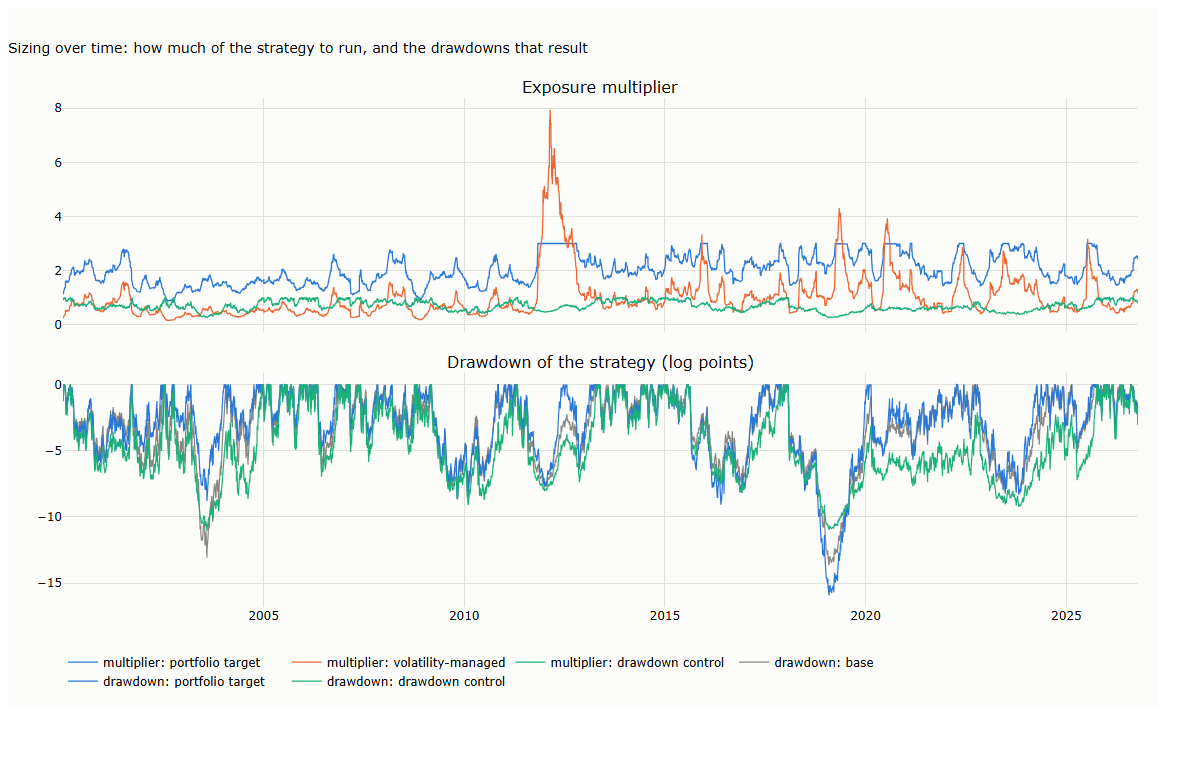

In [9]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                    subplot_titles=("Exposure multiplier", "Drawdown of the strategy (log points)"))
for j, c_ in enumerate(mult.columns):
    fig.add_scatter(x=mult.index, y=mult[c_], name=f"multiplier: {c_}", mode="lines", line=dict(width=1.3, color=SERIES[j]), row=1, col=1)
for j, (nm, x) in enumerate((("base", base), ("portfolio target", same_vol(port_target, base)), ("drawdown control", same_vol(dd_ctrl, base)))):
    cum = x.loc[START:].cumsum()
    fig.add_scatter(x=cum.index, y=100 * (cum - cum.cummax()), name=f"drawdown: {nm}", mode="lines", line=dict(width=1.2, color=[MUTED, SERIES[0], SERIES[2]][j]), row=2, col=1)
fig.update_layout(title="Sizing over time: how much of the strategy to run, and the drawdowns that result", height=700, width=1150,
                  margin=dict(t=90), legend=dict(orientation="h", y=-0.08, x=0))
save_figure(fig, "09_01_over_time", FIG)
fig

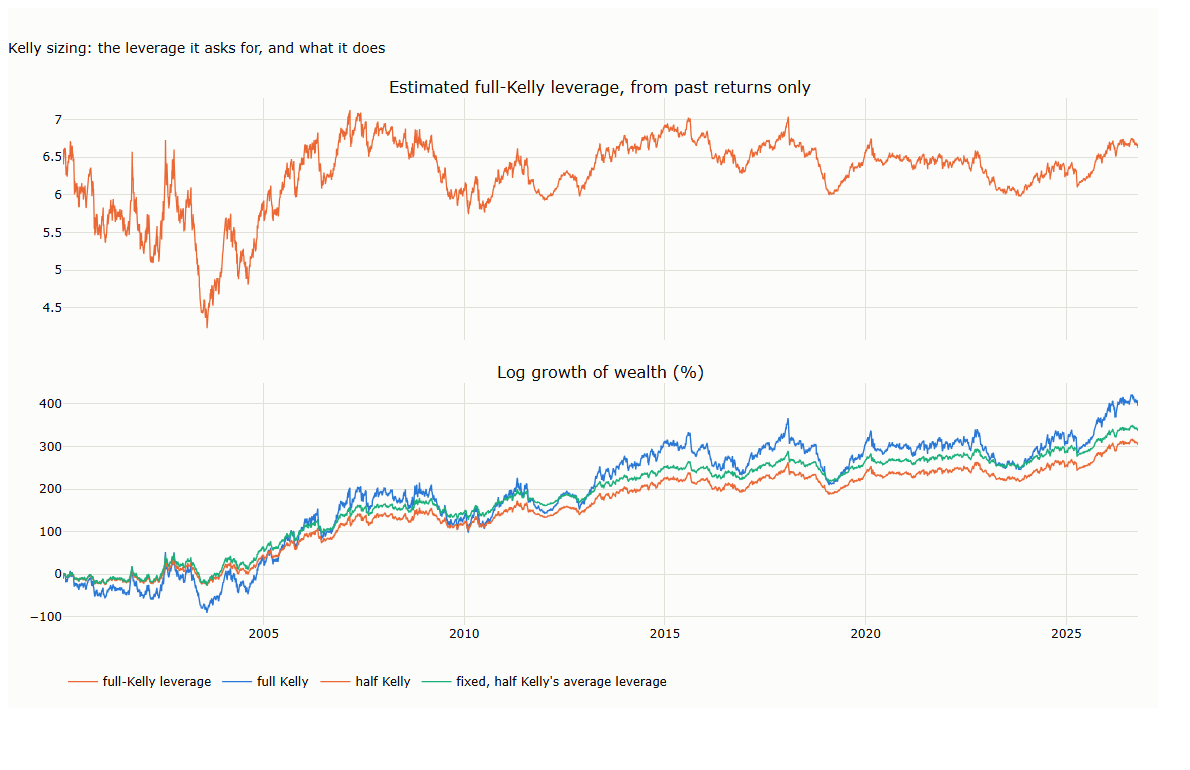

In [10]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                    subplot_titles=("Estimated full-Kelly leverage, from past returns only", "Log growth of wealth (%)"))
fig.add_scatter(x=f_full.loc[START:].index, y=f_full.loc[START:], name="full-Kelly leverage", mode="lines", line=dict(width=1.3, color=SERIES[1]), row=1, col=1)
for j, (nm, x) in enumerate((("full Kelly", kelly_full), ("half Kelly", kelly_half), ("fixed, half Kelly's average leverage", fixed))):
    fig.add_scatter(x=x.index, y=100 * x.cumsum(), name=nm, mode="lines", line=dict(width=1.4, color=SERIES[j]), row=2, col=1)
fig.update_layout(title="Kelly sizing: the leverage it asks for, and what it does", height=700, width=1150, margin=dict(t=90),
                  legend=dict(orientation="h", y=-0.08, x=0))
save_figure(fig, "09_02_kelly", FIG)
fig